In [7]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

### Задание №1

# ЛР №7. Задание 1

Найти численное решение ОДУ методом Эйлера (на равномерной сетке) и сравнить его с аналитическим решением.

## Исходная задача

$
\begin{cases}
\dfrac{dy}{dx} = x^2,\\
y(0)=1.
\end{cases}
$

## Метод Эйлера

Формула метода:

$
y_{i+1}=y_i+h\,f(x_i,y_i).
$

Для данной задачи

$
f(x,y)=x^2,
$

поэтому

$
y_{i+1}=y_i+h\,x_i^2.
$

Сетка:

$
x_i=x_0+i\,h.
$

Начальное условие:

$
x_0=0,\qquad y_0=1.
$



In [8]:
N = 100
a = 0
b = 3
y_k_1 = 0
y_k = 1
h = (b - a)/N
y_lin = []

x_lin = np.linspace(a, b, N)
x = sp.symbols('x')
f = x**2
for idx in x_lin:
    y_k_1 = y_k + h * f.subs(x, idx)
    y_lin.append(y_k)
    y_k = y_k_1

Аналитическое решение:

$$
\begin{aligned}
\frac{dy}{dx}=x^2, \ \ y(0)=1 \\
dy = x^2 dx \\
y = \frac{1}{3}x^3 + C, \ \ C=1 \\
y = \frac{1}{3}x^3 + 1
\end{aligned}
$$

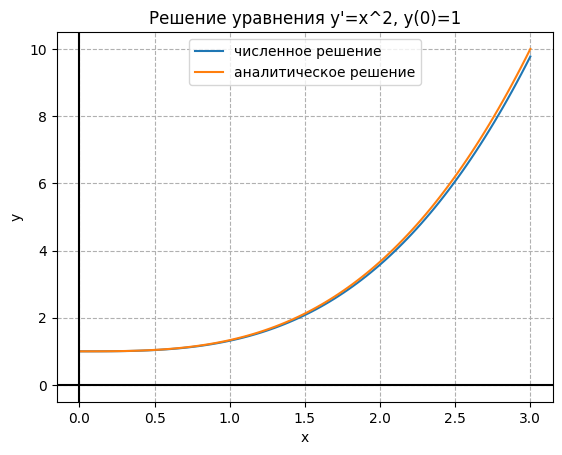

In [9]:
y_analyt = 1/3 * x_lin**3 + 1

plt.plot(x_lin, y_lin, label='численное решение')
plt.plot(x_lin, y_analyt, label='аналитическое решение')
plt.title("Решение уравнения y'=x^2, y(0)=1")
plt.ylabel("y")
plt.xlabel("x")
plt.axhline(y=0, color='black', linewidth=1.5)
plt.axvline(x=0, color='black', linewidth=1.5)
plt.legend()
plt.grid(ls="--")
plt.show()

### Задание №2

Дано дифференциальное уравнение второго порядка, сведём его к системе и применим солвер, основанный на формуле Рунге-Кутты

$$
\begin{cases}
y'' + 2y' + 10y = sint \\
y(0)=1, \ \ y'(0)=0
\end{cases}
$$

$$
\begin{cases}
y'_1 = y_2 \\
y'_2 = -2y_2 - 10y_1 + sint \\
y_1(0)=1, \ \ y_2(0)=0
\end{cases}
$$

$$
\begin{cases}
y'_1 = y_2 \\
y'_2 = -2y_2 - 10y_1 + sint \\
y_1(0)=1, \ \ y_2(0)=0
\end{cases}
$$

Сравним аналитическое и численное решения для $y_1, \ y_2$ солвера, который использует формулы Рунге-Кутты 4, 5 порядков

In [10]:
def create_compare_beetween_methods(sol, y_an_speed, y_an_cord, t_an):
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    axs[0].plot(sol.t, sol.y[0], label='численное решение', color='green', linewidth=2.75)
    axs[0].plot(t_an, y_an_cord, label='аналитическое решение', color='orange', linestyle='--', linewidth=1.25)
    axs[0].axhline(y=0, color='black', linewidth=1.5)
    axs[0].axvline(x=0, color='black', linewidth=1.5)
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('y')
    axs[0].set_title('численного vs аналитическоe решениe \n для  y_1(t)')
    axs[0].legend()
    axs[0].grid(ls="--")

    axs[1].plot(sol.t, sol.y[1], label='численное решение', color='green', linewidth=2.75)
    axs[1].plot(t_an, y_an_speed, label='аналитическое решение', color='orange', linestyle='--', linewidth=1.25)
    axs[1].axhline(y=0, color='black', linewidth=1.5)
    axs[1].axvline(x=0, color='black', linewidth=1.5)
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('y')
    axs[1].set_title('численного vs аналитическоe решениe \n для скорости y_2(t)')
    axs[1].legend()
    axs[1].grid(ls="--")

    plt.tight_layout()
    plt.show()

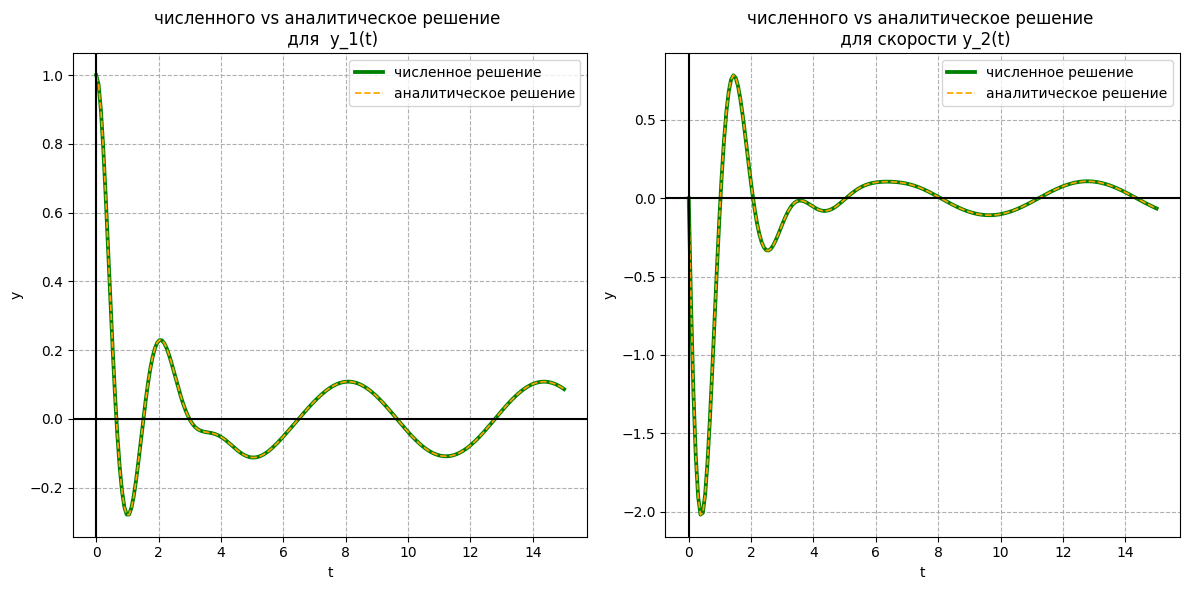

In [11]:
def system(t, y):
    dy1_dt = y[1]
    dy2_dt = -2 * y[1] - 10 * y[0] + np.sin(t)
    return [dy1_dt, dy2_dt]


y0 = [1, 0]
t_span = (0, 15)
t_eval = np.linspace(0, 15, 200)

sol_45 = solve_ivp(system, t_span, y0, method='RK45', t_eval=t_eval)

C1 = 87/85
C2 = 26/85
x = sp.symbols('x')
y_analyt_expr = sp.exp(-x) * (C1 * sp.cos(3*x) + C2 * sp.sin(3*x)) + 1/85 * (9 * sp.sin(x) - 2 * sp.cos(x))
y_analyt_expr_d = sp.diff(y_analyt_expr, x)

y_analyt_cord_lamd = sp.lambdify(x, y_analyt_expr, 'numpy')
y_analyt_cord = y_analyt_cord_lamd(t_eval)

y_analyt_speed_lamd = sp.lambdify(x, y_analyt_expr_d, 'numpy')
y_analyt_speed = y_analyt_speed_lamd(t_eval)

create_compare_beetween_methods(sol_45, y_analyt_speed, y_analyt_cord, t_eval)

сравнение, только для солвера, использующего формулы Рунге-Кутты 2, 3 порядков

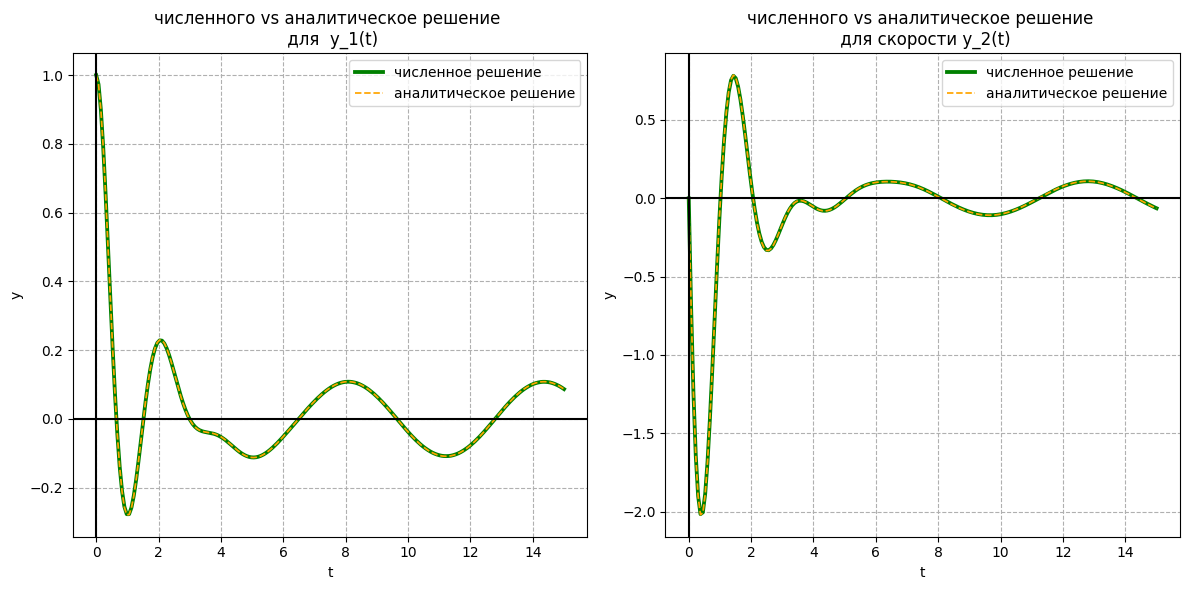

In [12]:
sol_23 = solve_ivp(system, t_span, y0, method='RK23', t_eval=t_eval)
create_compare_beetween_methods(sol_23, y_analyt_speed, y_analyt_cord, t_eval)

Внешне кажется, что солверы с методами RK23, RK45 одинаково приближают аналитическое решение, но чтобы убедиться во влиянии порядков формул, построим график ошибок

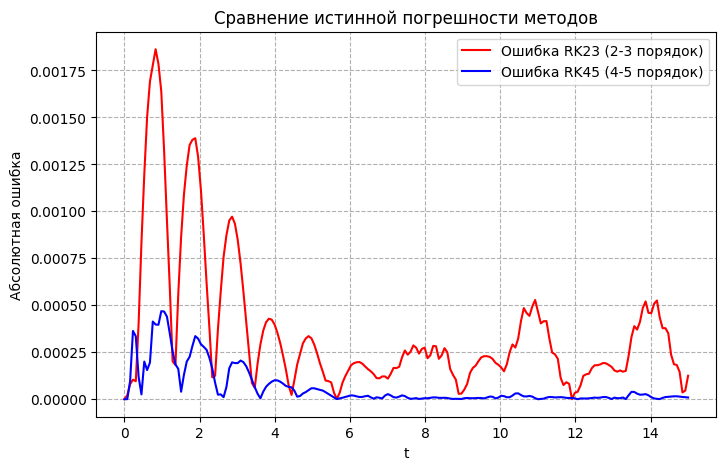

In [13]:
error_rk23 = np.abs(sol_23.y[0] - y_analyt_cord)
error_rk45 = np.abs(sol_45.y[0] - y_analyt_cord)

plt.figure(figsize=(8, 5))
plt.plot(t_eval, error_rk23, label='Ошибка RK23 (2-3 порядок)', color='red')
plt.plot(t_eval, error_rk45, label='Ошибка RK45 (4-5 порядок)', color='blue')
plt.xlabel('t')
plt.ylabel('Абсолютная ошибка')
plt.title('Сравнение истинной погрешности методов')
plt.legend()
plt.grid(ls="--")
plt.show()

### Задание №3

$$
\begin{cases}
y'' = - \frac{1}{t^2} \\
y(0.01)=ln(0.01)
\end{cases}
$$

$$
\begin{cases}
y'_1 = y_2 \\
y'_2 = - \frac{1}{t^2} \\
y(0.01)=ln(0.01)
\end{cases}
$$

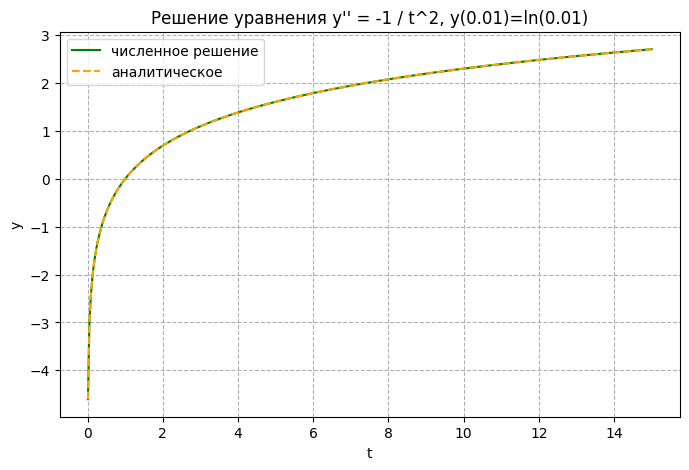

In [14]:
def system(t, y):
    dy1_dt = y[1]
    dy2_dt = -1 / t**2
    return [dy1_dt, dy2_dt]

t0 = 0.01
y0 = [np.log(t0), 1 / t0]
t_span = (0.01, 15)
t_eval = np.linspace(0.01, 15, 400)


sol_45_log = solve_ivp(system, t_span, y0, method='RK45', t_eval=t_eval, rtol=1e-10, atol=1e-12, max_step=0.05 )

y_log_lin = np.log(t_eval)

plt.figure(figsize=(8, 5))
plt.plot(sol_45_log.t, sol_45_log.y[0], label='численное решение', color='green')
plt.plot(t_eval, y_log_lin, label='аналитическое', color='orange', ls="--")
plt.xlabel('t')
plt.ylabel('y')
plt.title("Решение уравнения y'' = -1 / t^2, y(0.01)=ln(0.01)")
plt.legend()
plt.grid(ls="--")
plt.show()

У солвера есть функция - контроль точности на каждой итерации, как я понял он работает за счёт подсчёта решения по формуле одного порядка и большего порядка, допустим в RK45 считается значение по формуле 4-го порядка и 5-го порядка: $$ e=|y_{выс}-y_{низ}|$$  $$ e \leq atol + rtol \cdot |y|$$ где atol - абсолютная ошибка, rtol - относительная ошибка и если задать жёсткий контроль в начале, то в конце не будет большого расхождения